# The Batch-Size Trade-Off | Does More Frequent Updating Improve Learning?

*An experimental portfolio entry using Fashion-MNIST and PyTorch*

## The question

If a neural network sees the same training examples for the same number of epochs, does changing the batch size alter how it learns? A small batch causes the optimizer to update the model more often, while a large batch averages information from more examples before each update. I compare batch sizes of **16, 64, and 256** to see how this affects learning curves, validation performance, and training time.

The aim is to observe this trade-off under fixed conditions.

## 1. What batch size changes

A *batch* is the group of training examples processed together before the optimizer changes the model's parameters. During training, the network makes predictions, calculates a loss, and computes gradients. The optimizer uses those gradients to update the weights.

For a mini-batch containing \(B\) examples, the average gradient is

\[
g_t = \frac{1}{B}\sum_{i=1}^{B}\nabla_{\theta}\mathcal{L}_i(\theta_t),
\]

where \(B\) is the batch size, \(\theta_t\) represents the model parameters at update \(t\), and \(\mathcal{L}_i\) is the loss for example \(i\). A basic gradient-descent update is

\[
\theta_{t+1} = \theta_t - \eta g_t,
\]

where \(\eta\) is the learning rate.

Smaller batches produce noisier gradient estimates but allow more frequent updates. Larger batches average more examples per update, which can make estimates less noisy but reduces the number of updates per epoch. They may also use hardware more efficiently, at the cost of more memory.

An *epoch* is one complete pass through the training set. With \(N\) training examples and batch size \(B\), the number of updates in one epoch is

\[
U_{\text{epoch}} = \left\lceil \frac{N}{B} \right\rceil.
\]

Therefore, equal epoch counts do not imply equal numbers of optimizer updates. This is the central idea tested here.

## 2. Experimental design

### Dataset and split

I use Fashion-MNIST, a collection of 28 × 28 grayscale images from ten clothing categories. The official training portion contains 60,000 images and the official test portion contains 10,000. I reserve 5,000 images from the training portion for validation, then use a fixed 10,000-image subset of the remaining training data to keep the experiment manageable. The official test set is not used to choose or compare batch sizes.

### Model and controlled settings

The classifier is a small **multilayer perceptron (MLP)**, not a CNN. It flattens each image into 784 input values, uses two fully connected hidden layers (256 and 128 units) with ReLU activations and dropout, and produces ten class scores. The model has approximately 235,000 trainable parameters. The same architecture and initialization seed are used for each paired comparison.

The independent variable is batch size: **16, 64, or 256**. The controlled settings are:

| Setting | Value |
|---|---|
| Dataset | Fashion-MNIST |
| Training subset | 10,000 images |
| Validation set | 5,000 images |
| Model | MLP: 784 → 256 → 128 → 10 |
| Hidden activation | ReLU |
| Dropout | 0.25 |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Weight decay | 0 |
| Epochs | 4 |
| Batch sizes | 16, 64, 256 |
| Random seeds | 42, 123, 2026 |
| Data augmentation | None |

Each batch size is repeated with three seeds, giving nine runs. The fixed training and validation examples are reused throughout, and model initialization is seed-matched across batch sizes. Only batch size changes within each paired comparison. Runtime is hardware-specific.

## 3. Run the experiment

The cells below create the fixed split, define the MLP, train all nine configurations, and record sample-weighted metrics. The test set remains untouched. Run from top to bottom to regenerate results and figures.

In [1]:
%pip -q install torch torchvision pandas matplotlib

In [2]:
import os
import time
import random
import math
import platform
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "./data"
OUTPUT_DIR = "./batch_size_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

Python: 3.13.16
PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


### 3.1 Reproducibility and data preparation

The data split is generated once with a dedicated random seed and reused across all nine runs. Each repetition has its own seed for model initialization and training-data shuffling. This paired design makes the batch-size comparisons more consistent: within a seed, the three settings use the same training and validation examples. The official test set is kept separate and is not used to select or compare configurations.

In [3]:
# Fixed experiment settings
@dataclass
class ExperimentConfig:
    train_subset: int = 10_000
    validation_size: int = 5_000
    epochs: int = 4
    learning_rate: float = 1e-3
    dropout: float = 0.25
    weight_decay: float = 0.0
    batch_sizes: tuple = (16, 64, 256)
    seeds: tuple = (42, 123, 2026)
    split_seed: int = 31415
    num_workers: int = 0

CFG = ExperimentConfig()
print(pd.Series(asdict(CFG)))

train_subset                 10000
validation_size               5000
epochs                           4
learning_rate                0.001
dropout                       0.25
weight_decay                   0.0
batch_sizes          (16, 64, 256)
seeds              (42, 123, 2026)
split_seed                   31415
num_workers                      0
dtype: object


In [4]:
# Fashion-MNIST is converted to tensors.
# ToTensor scales pixel values to [0, 1]; no augmentation is applied.
transform = transforms.ToTensor()

full_train_dataset = datasets.FashionMNIST(
    root=DATA_DIR, train=True, download=True, transform=transform
)
test_dataset = datasets.FashionMNIST(
    root=DATA_DIR, train=False, download=True, transform=transform
)

train_pool_size = len(full_train_dataset) - CFG.validation_size
assert CFG.train_subset <= train_pool_size

split_generator = torch.Generator().manual_seed(CFG.split_seed)
train_pool, validation_dataset = random_split(
    full_train_dataset,
    [train_pool_size, CFG.validation_size],
    generator=split_generator
)

# Select the same 10,000 training examples for every run.
subset_generator = torch.Generator().manual_seed(CFG.split_seed + 1)
selected_positions = torch.randperm(
    len(train_pool), generator=subset_generator
)[:CFG.train_subset].tolist()
train_dataset = Subset(train_pool, selected_positions)

print(f"Full official training set: {len(full_train_dataset):,}")
print(f"Training pool after validation split: {len(train_pool):,}")
print(f"Training subset used in experiments: {len(train_dataset):,}")
print(f"Validation set: {len(validation_dataset):,}")
print(f"Reserved official test set: {len(test_dataset):,}")

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 171kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.17MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.0MB/s]

Full official training set: 60,000
Training pool after validation split: 55,000
Training subset used in experiments: 10,000
Validation set: 5,000
Reserved official test set: 10,000


### 3.2 Model architecture

The classifier is a multilayer perceptron (MLP). Each 28 × 28 image is flattened into a vector of 784 pixel values, then passed through fully connected layers with 256 and 128 hidden units. ReLU activations introduce non-linearity, dropout is applied after each hidden activation, and the final layer produces ten class scores. Because the network contains no convolutional layers, it is not a convolutional neural network (CNN).

In [5]:
class FashionMLP(nn.Module):
    def __init__(self, dropout=0.25):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def make_loaders(batch_size, seed):
    # A dedicated generator makes shuffling reproducible for each run.
    train_generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=CFG.num_workers,
        pin_memory=(DEVICE.type == "cuda"),
        generator=train_generator
    )
    val_loader = DataLoader(
        validation_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=CFG.num_workers,
        pin_memory=(DEVICE.type == "cuda")
    )
    return train_loader, val_loader

# Number of trainable parameters in the fixed MLP architecture.
model_for_count = FashionMLP(dropout=CFG.dropout)
parameter_count = sum(p.numel() for p in model_for_count.parameters() if p.requires_grad)
print(f"Trainable parameters: {parameter_count:,}")


Trainable parameters: 235,146


### 3.3 Training and evaluation

The model is trained with Adam and cross-entropy loss. Training loss and accuracy are accumulated per example, so a smaller final batch is weighted correctly rather than counted as if it contained a full batch. Validation runs in evaluation mode with gradient calculation disabled; validation data never updates the model. Runtime includes all training epochs and validation passes, but excludes dataset download and initial setup.

In [7]:
def run_one_experiment(batch_size, seed):
    set_seed(seed)
    model = FashionMLP(dropout=CFG.dropout).to(DEVICE)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=CFG.learning_rate,
        weight_decay=CFG.weight_decay
    )
    criterion = nn.CrossEntropyLoss()
    train_loader, val_loader = make_loaders(batch_size, seed)

    history = []
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(1, CFG.epochs + 1):
        # Training phase
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_count = 0

        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            batch_count = labels.size(0)
            train_loss_sum += loss.item() * batch_count
            train_correct += (logits.argmax(dim=1) == labels).sum().item()
            train_count += batch_count

        # Validation phase: no parameter updates occur here.
        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_count = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                logits = model(images)
                loss = criterion(logits, labels)

                batch_count = labels.size(0)
                val_loss_sum += loss.item() * batch_count
                val_correct += (logits.argmax(dim=1) == labels).sum().item()
                val_count += batch_count

        history.append({
            "epoch": epoch,
            "train_loss": train_loss_sum / train_count,
            "train_accuracy": train_correct / train_count,
            "val_loss": val_loss_sum / val_count,
            "val_accuracy": val_correct / val_count
        })

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    updates_per_epoch = len(train_loader)
    total_updates = updates_per_epoch * CFG.epochs

    return {
        "batch_size": batch_size,
        "seed": seed,
        "train_samples": len(train_dataset),
        "validation_samples": len(validation_dataset),
        "updates_per_epoch": updates_per_epoch,
        "total_updates": total_updates,
        "training_seconds": elapsed,
        "history": pd.DataFrame(history)
    }

### 3.4 Experimental runs

Each of the three random seeds is evaluated with all three batch sizes, producing nine runs in total. Within each seed, batch size is the only experimental setting that changes. The training subset, validation set, model architecture, optimizer, learning rate, dropout, and epoch count remain fixed.

In [8]:
runs = []
run_histories = []

for seed in CFG.seeds:
    for batch_size in CFG.batch_sizes:
        print(f"Running batch_size={batch_size}, seed={seed} ...")
        result = run_one_experiment(batch_size=batch_size, seed=seed)
        runs.append(result)

        history = result["history"].copy()
        history["batch_size"] = batch_size
        history["seed"] = seed
        run_histories.append(history)

        best_row = history.loc[history["val_accuracy"].idxmax()]
        print(
            f"  best validation accuracy={best_row['val_accuracy']:.4f}; "
            f"time={result['training_seconds']:.1f}s; "
            f"updates={result['total_updates']:,}"
        )

history_df = pd.concat(run_histories, ignore_index=True)

# One row per run, using the best validation accuracy across its epochs.
result_rows = []
for result in runs:
    h = result["history"]
    best_idx = h["val_accuracy"].idxmax()
    best = h.loc[best_idx]
    final = h.iloc[-1]
    result_rows.append({
        "batch_size": result["batch_size"],
        "seed": result["seed"],
        "train_samples": result["train_samples"],
        "validation_samples": result["validation_samples"],
        "updates_per_epoch": result["updates_per_epoch"],
        "total_updates": result["total_updates"],
        "best_epoch": int(best["epoch"]),
        "best_val_accuracy": best["val_accuracy"],
        "final_val_accuracy": final["val_accuracy"],
        "final_val_loss": final["val_loss"],
        "final_train_accuracy": final["train_accuracy"],
        "final_train_loss": final["train_loss"],
        "training_seconds": result["training_seconds"]
    })

results_df = pd.DataFrame(result_rows).sort_values(["batch_size", "seed"])
display(results_df)

Running batch_size=16, seed=42 ...
  best validation accuracy=0.8460; time=12.5s; updates=2,500
Running batch_size=64, seed=42 ...
  best validation accuracy=0.8380; time=7.2s; updates=628
Running batch_size=256, seed=42 ...
  best validation accuracy=0.8230; time=6.2s; updates=160
Running batch_size=16, seed=123 ...
  best validation accuracy=0.8376; time=12.1s; updates=2,500
Running batch_size=64, seed=123 ...
  best validation accuracy=0.8302; time=6.7s; updates=628
Running batch_size=256, seed=123 ...
  best validation accuracy=0.8164; time=6.4s; updates=160
Running batch_size=16, seed=2026 ...
  best validation accuracy=0.8360; time=12.1s; updates=2,500
Running batch_size=64, seed=2026 ...
  best validation accuracy=0.8366; time=6.7s; updates=628
Running batch_size=256, seed=2026 ...
  best validation accuracy=0.8150; time=6.3s; updates=160


,batch_size,seed,train_samples,validation_samples,updates_per_epoch,total_updates,best_epoch,best_val_accuracy,final_val_accuracy,final_val_loss,final_train_accuracy,final_train_loss,training_seconds
0,16,42,10000,5000,625,2500,4,0.8460,0.8460,0.424733,0.8399,0.442749,12.548848
3,16,123,10000,5000,625,2500,4,0.8376,0.8376,0.453139,0.8389,0.444036,12.098336
6,16,2026,10000,5000,625,2500,4,0.8360,0.8360,0.457857,0.8344,0.445338,12.062620
1,64,42,10000,5000,157,628,4,0.8380,0.8380,0.459659,0.8328,0.459370,7.207514
4,64,123,10000,5000,157,628,4,0.8302,0.8302,0.467535,0.8347,0.456190,6.714186
7,64,2026,10000,5000,157,628,4,0.8366,0.8366,0.444543,0.8357,0.456485,6.685175
2,256,42,10000,5000,40,160,4,0.8230,0.8230,0.509216,0.7979,0.556787,6.222924
5,256,123,10000,5000,40,160,4,0.8164,0.8164,0.515291,0.8052,0.550943,6.412369
8,256,2026,10000,5000,40,160,4,0.8150,0.8150,0.507910,0.7984,0.554875,6.274735


## 4. Results

The figures summarize all nine runs. Learning curves show the mean across the three seeds, with shaded regions representing plus or minus one standard deviation. The shading describes variation across these repetitions; it is not a formal confidence interval.

In [9]:
curve_summary = (
    history_df
    .groupby(["batch_size", "epoch"])
    .agg(
        train_loss_mean=("train_loss", "mean"),
        train_loss_std=("train_loss", "std"),
        val_loss_mean=("val_loss", "mean"),
        val_loss_std=("val_loss", "std"),
        train_acc_mean=("train_accuracy", "mean"),
        train_acc_std=("train_accuracy", "std"),
        val_acc_mean=("val_accuracy", "mean"),
        val_acc_std=("val_accuracy", "std")
    )
    .reset_index()
)

display(curve_summary)

,batch_size,epoch,train_loss_mean,train_loss_std,val_loss_mean,val_loss_std,train_acc_mean,train_acc_std,val_acc_mean,val_acc_std
0,16,1,0.797938,0.008669,0.560268,0.006049,0.704767,0.006596,0.796400,0.005370
1,16,2,0.540636,0.005899,0.483663,0.007003,0.803967,0.003925,0.822533,0.002928
2,16,3,0.483843,0.001339,0.457130,0.003117,0.821967,0.003607,0.828933,0.006110
3,16,4,0.444041,0.001295,0.445243,0.017918,0.837733,0.002930,0.839867,0.005372
4,64,1,0.939608,0.015111,0.593938,0.014982,0.656767,0.008317,0.788333,0.009069
5,64,2,0.585317,0.003403,0.524766,0.009557,0.787967,0.004291,0.812333,0.003372
6,64,3,0.502139,0.004174,0.468578,0.002853,0.817933,0.002312,0.828667,0.001172
7,64,4,0.457348,0.001757,0.457245,0.011684,0.834400,0.001473,0.834933,0.004159
8,256,1,1.298338,0.029989,0.739141,0.014658,0.547100,0.019053,0.728333,0.013543
9,256,2,0.729669,0.010970,0.607173,0.012601,0.731033,0.007125,0.785867,0.009433


### Figure 1. Training and validation loss

The x-axis is epoch and the y-axis is cross-entropy loss. Lower loss indicates better fit to labels. Training loss is measured on examples used for updates; validation loss is measured on held-out examples.

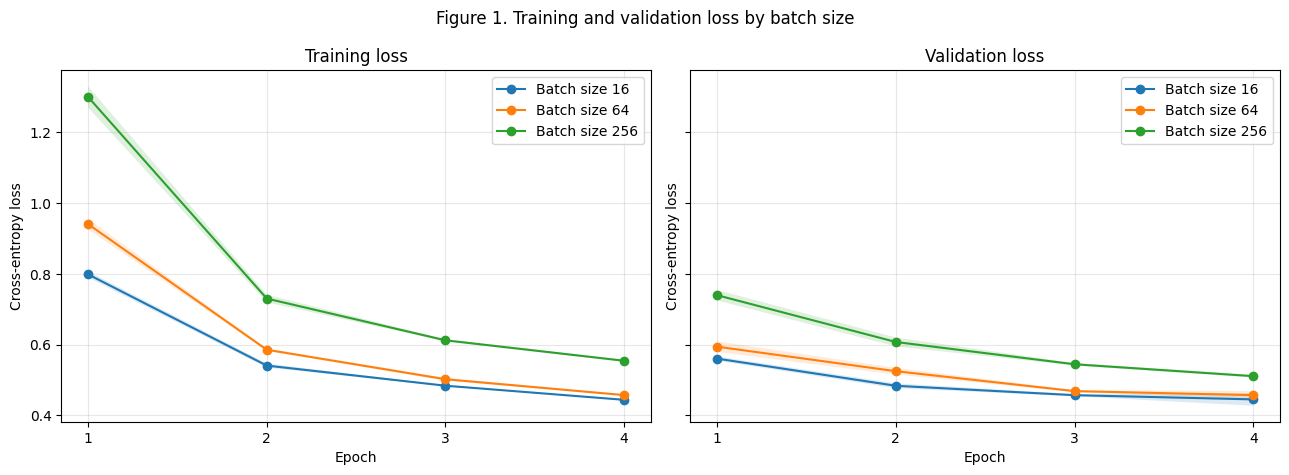

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

for ax, mean_col, std_col, title in [
    (axes[0], "train_loss_mean", "train_loss_std", "Training loss"),
    (axes[1], "val_loss_mean", "val_loss_std", "Validation loss")
]:
    for batch_size in CFG.batch_sizes:
        d = curve_summary[curve_summary.batch_size == batch_size].sort_values("epoch")
        x = d["epoch"].to_numpy()
        mean = d[mean_col].to_numpy()
        std = d[std_col].fillna(0).to_numpy()
        ax.plot(x, mean, marker="o", label=f"Batch size {batch_size}")
        ax.fill_between(x, mean - std, mean + std, alpha=0.15)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.set_xticks(range(1, CFG.epochs + 1))
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("Figure 1. Training and validation loss by batch size")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure_1_loss_curves.png"), dpi=200, bbox_inches="tight")
plt.show()

### Figure 2. Training and validation accuracy

The y-axis is classification accuracy. Comparing training and validation curves shows whether improvements on training examples also appear on unseen validation examples. A gap may indicate weaker generalization.

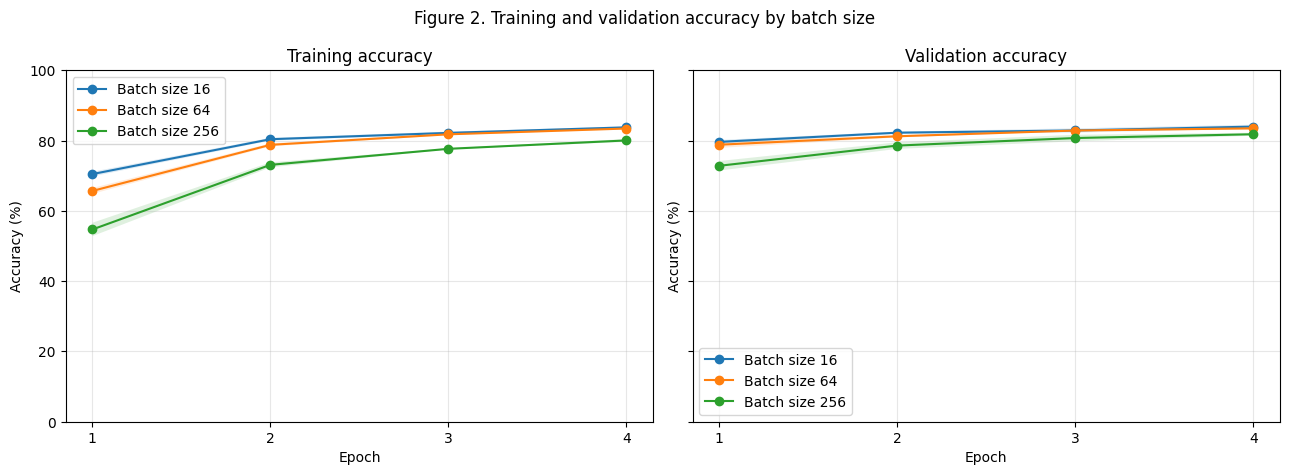

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

for ax, mean_col, std_col, title in [
    (axes[0], "train_acc_mean", "train_acc_std", "Training accuracy"),
    (axes[1], "val_acc_mean", "val_acc_std", "Validation accuracy")
]:
    for batch_size in CFG.batch_sizes:
        d = curve_summary[curve_summary.batch_size == batch_size].sort_values("epoch")
        x = d["epoch"].to_numpy()
        mean = d[mean_col].to_numpy() * 100
        std = d[std_col].fillna(0).to_numpy() * 100
        ax.plot(x, mean, marker="o", label=f"Batch size {batch_size}")
        ax.fill_between(x, mean - std, mean + std, alpha=0.15)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.set_ylim(0, 100)
    ax.set_xticks(range(1, CFG.epochs + 1))
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("Figure 2. Training and validation accuracy by batch size")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure_2_accuracy_curves.png"), dpi=200, bbox_inches="tight")
plt.show()

### Figure 3. Optimizer updates

This figure shows the number of optimizer updates per epoch and across the full four-epoch run. The number of updates is determined by the number of training examples and the batch size, not by model accuracy.

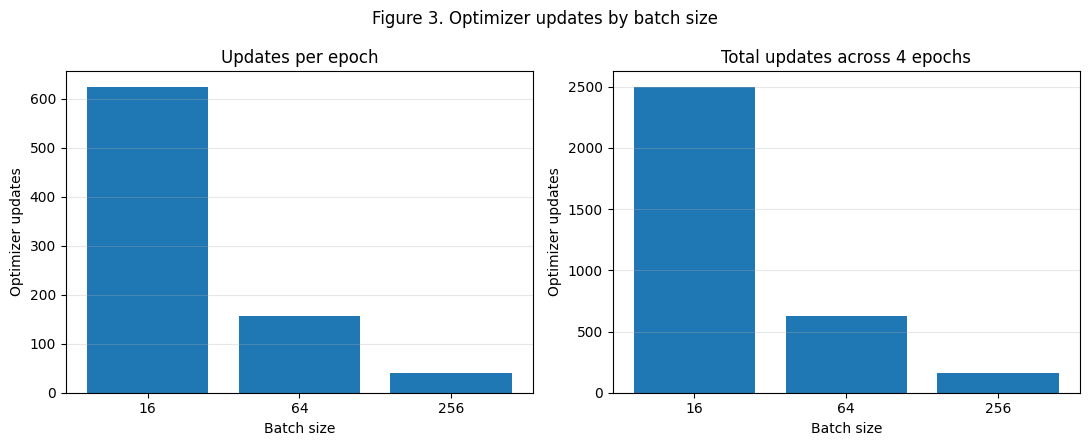

,batch_size,updates_per_epoch,total_updates
0,16,625.0,2500.0
1,64,157.0,628.0
2,256,40.0,160.0


In [12]:
update_table = (
    results_df.groupby("batch_size", as_index=False)
    .agg(
        updates_per_epoch=("updates_per_epoch", "mean"),
        total_updates=("total_updates", "mean")
    )
    .sort_values("batch_size")
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(update_table["batch_size"].astype(str), update_table["updates_per_epoch"])
axes[0].set_title("Updates per epoch")
axes[0].set_xlabel("Batch size")
axes[0].set_ylabel("Optimizer updates")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(update_table["batch_size"].astype(str), update_table["total_updates"])
axes[1].set_title(f"Total updates across {CFG.epochs} epochs")
axes[1].set_xlabel("Batch size")
axes[1].set_ylabel("Optimizer updates")
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle("Figure 3. Optimizer updates by batch size")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure_3_optimizer_updates.png"), dpi=200, bbox_inches="tight")
plt.show()

display(update_table)

### Figure 4. Training time

Bars show mean training-and-validation time across three seeds; error bars show one standard deviation. Timing depends on hardware, background load, software, and data-loader settings.

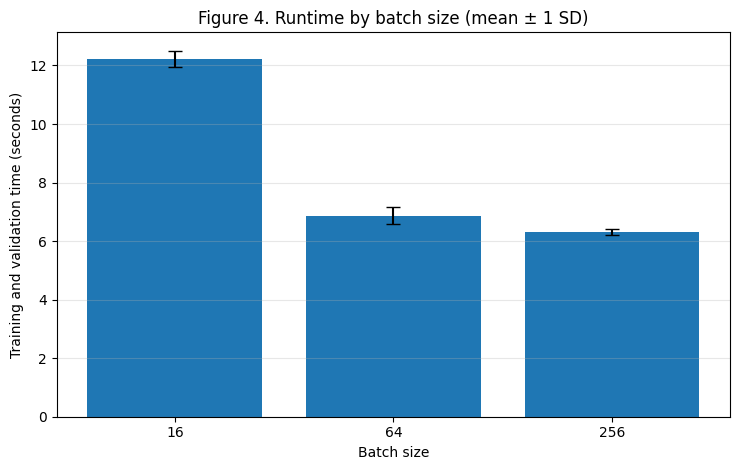

,batch_size,mean_seconds,std_seconds
0,16,12.236601,0.271002
1,64,6.868958,0.293556
2,256,6.303343,0.097909


In [13]:
time_table = (
    results_df.groupby("batch_size", as_index=False)
    .agg(
        mean_seconds=("training_seconds", "mean"),
        std_seconds=("training_seconds", "std")
    )
    .sort_values("batch_size")
)

plt.figure(figsize=(7.5, 4.8))
plt.bar(
    time_table["batch_size"].astype(str),
    time_table["mean_seconds"],
    yerr=time_table["std_seconds"],
    capsize=5
)
plt.xlabel("Batch size")
plt.ylabel("Training and validation time (seconds)")
plt.title("Figure 4. Runtime by batch size (mean ± 1 SD)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figure_4_training_time.png"), dpi=200, bbox_inches="tight")
plt.show()

display(time_table)

## 5. Summary and discussion

The tables report results across the three random seeds. Best validation accuracy is calculated separately for each run by selecting its highest validation accuracy across the four epochs; the summary then reports the mean and standard deviation across seeds. Final-epoch validation metrics are also retained so that the best checkpoint metric is not confused with the last-epoch metric.

In [14]:
summary_table = (
    results_df.groupby("batch_size")
    .agg(
        best_val_accuracy_mean=("best_val_accuracy", "mean"),
        best_val_accuracy_std=("best_val_accuracy", "std"),
        final_val_accuracy_mean=("final_val_accuracy", "mean"),
        final_val_loss_mean=("final_val_loss", "mean"),
        mean_training_seconds=("training_seconds", "mean"),
        std_training_seconds=("training_seconds", "std"),
        updates_per_epoch=("updates_per_epoch", "mean"),
        total_updates=("total_updates", "mean")
    )
    .reset_index()
)

summary_table["best_val_accuracy_mean_pct"] = summary_table["best_val_accuracy_mean"] * 100
summary_table["best_val_accuracy_std_pp"] = summary_table["best_val_accuracy_std"] * 100

display(summary_table.round(4))

,batch_size,best_val_accuracy_mean,best_val_accuracy_std,final_val_accuracy_mean,final_val_loss_mean,mean_training_seconds,std_training_seconds,updates_per_epoch,total_updates,best_val_accuracy_mean_pct,best_val_accuracy_std_pp
0,16,0.8399,0.0054,0.8399,0.4452,12.2366,0.2710,625.0,2500.0,83.9867,0.5372
1,64,0.8349,0.0042,0.8349,0.4572,6.8690,0.2936,157.0,628.0,83.4933,0.4159
2,256,0.8181,0.0043,0.8181,0.5108,6.3033,0.0979,40.0,160.0,81.8133,0.4272


## 6. Quantitative comparison

The following results compare validation performance, elapsed training time, and optimizer-update counts. Validation accuracy is the selection metric; the official test set remains unused. The accompanying interpretation is generated from the measurements produced by this notebook.

In [15]:
best_row = summary_table.loc[summary_table["best_val_accuracy_mean"].idxmax()]
fastest_row = summary_table.loc[summary_table["mean_training_seconds"].idxmin()]

print("Measured results (mean across three seeds)\n")
for _, row in summary_table.sort_values("batch_size").iterrows():
    print(
        f"Batch size {int(row.batch_size)}: "
        f"best validation accuracy {row.best_val_accuracy_mean * 100:.2f}% "
        f"(SD {row.best_val_accuracy_std * 100:.2f} percentage points); "
        f"final validation accuracy {row.final_val_accuracy_mean * 100:.2f}%; "
        f"mean runtime {row.mean_training_seconds:.2f} seconds; "
        f"{int(row.updates_per_epoch)} updates per epoch."
    )

accuracy_gap = (
    best_row.best_val_accuracy_mean
    - summary_table["best_val_accuracy_mean"].min()
) * 100
print("\nData-based interpretation")
print(
    f"Batch size {int(best_row.batch_size)} had the highest mean best-validation "
    f"accuracy ({best_row.best_val_accuracy_mean * 100:.2f}%). The difference "
    f"between the highest and lowest batch-size means was {accuracy_gap:.2f} "
    "percentage points."
)
print(
    f"Batch size {int(fastest_row.batch_size)} had the shortest mean measured "
    f"runtime ({fastest_row.mean_training_seconds:.2f} seconds)."
)

# Summarize the direction of the mean loss curves without assuming an outcome.
print("\nLearning-curve trends")
for batch_size in CFG.batch_sizes:
    curve = curve_summary[
        curve_summary.batch_size == batch_size
    ].sort_values("epoch")
    train_change = curve.train_loss_mean.iloc[-1] - curve.train_loss_mean.iloc[0]
    val_change = curve.val_loss_mean.iloc[-1] - curve.val_loss_mean.iloc[0]
    train_word = "decreased" if train_change < 0 else "increased" if train_change > 0 else "was unchanged"
    val_word = "decreased" if val_change < 0 else "increased" if val_change > 0 else "was unchanged"
    print(
        f"Batch size {batch_size}: mean training loss {train_word} "
        f"by {abs(train_change):.4f}; mean validation loss {val_word} "
        f"by {abs(val_change):.4f} from epoch 1 to epoch {CFG.epochs}."
    )

print("\nThe update counts follow ceil(N / B):")
for batch_size in CFG.batch_sizes:
    updates = math.ceil(CFG.train_subset / batch_size)
    print(
        f"Batch size {batch_size}: {updates} updates per epoch, "
        f"or {updates * CFG.epochs} over {CFG.epochs} epochs."
    )

Measured results (mean across three seeds)

Batch size 16: best validation accuracy 83.99% (SD 0.54 percentage points); final validation accuracy 83.99%; mean runtime 12.24 seconds; 625 updates per epoch.
Batch size 64: best validation accuracy 83.49% (SD 0.42 percentage points); final validation accuracy 83.49%; mean runtime 6.87 seconds; 157 updates per epoch.
Batch size 256: best validation accuracy 81.81% (SD 0.43 percentage points); final validation accuracy 81.81%; mean runtime 6.30 seconds; 40 updates per epoch.

Data-based interpretation
Batch size 16 had the highest mean best-validation accuracy (83.99%). The difference between the highest and lowest batch-size means was 2.17 percentage points.
Batch size 256 had the shortest mean measured runtime (6.30 seconds).

Learning-curve trends
Batch size 16: mean training loss decreased by 0.3539; mean validation loss decreased by 0.1150 from epoch 1 to epoch 4.
Batch size 64: mean training loss decreased by 0.4823; mean validation lo

### 7. Interpreting the evidence

The learning curves show that all three batch-size configurations continued to improve throughout the four training epochs. Training and validation losses decreased from the first to the final epoch, indicating that the models were still learning when the experiment ended. Each configuration also achieved its highest validation accuracy at the fourth epoch. This suggests that the four-epoch training period may not have been sufficient to determine whether the models had reached their best possible performance. Additional epochs would be needed to observe whether the improvements eventually plateau.

The training and validation accuracy curves should also be interpreted with the model's dropout setting in mind. During training, dropout is active and randomly disables a proportion of hidden units to reduce overfitting. During validation, the model is in evaluation mode, so dropout is disabled. As a result, validation accuracy can be slightly higher than training accuracy because the model uses all hidden units during validation. Therefore, a small difference between the two curves does not automatically indicate a problem with the experiment or prove that overfitting is absent.

Overall, the learning curves support the numerical results: batch size 16 achieved the strongest validation performance, while batch size 256 trained in the shortest measured time. However, because the experiment used a fixed number of epochs, smaller batch sizes also performed more optimizer updates. The observed differences may therefore reflect both batch size and update frequency. These findings apply to the dataset subset, MLP architecture, optimizer, training schedule, and hardware used in this experiment.

### Limitations

This experiment uses a 10,000-image training subset rather than the full Fashion-MNIST training set, so its results may differ with more data. The MLP is a small fully connected model and does not exploit the spatial structure of images in the way a convolutional network can. Three seeds and four epochs provide a limited sample of possible training outcomes. Runtime also depends on hardware, software versions, background processes, and data-loading performance. Finally, batch size can interact with learning rate, optimizer choice, normalization, and other hyperparameters. The conclusions therefore apply to this experimental setup rather than to every neural network or dataset.

In [16]:
# Integrity checks: nine unique batch-size/seed combinations
expected_pairs = {
    (batch_size, seed)
    for batch_size in CFG.batch_sizes
    for seed in CFG.seeds
}
actual_pairs = set(zip(results_df["batch_size"], results_df["seed"]))

assert len(results_df) == 9, f"Expected 9 runs, found {len(results_df)}."
assert actual_pairs == expected_pairs, "Missing or duplicate batch-size/seed combinations."
assert results_df["train_samples"].eq(CFG.train_subset).all()
assert results_df["validation_samples"].eq(CFG.validation_size).all()

for batch_size in CFG.batch_sizes:
    expected_updates = math.ceil(CFG.train_subset / batch_size)
    subset = results_df[results_df.batch_size == batch_size]
    assert subset["updates_per_epoch"].eq(expected_updates).all()
    assert subset["total_updates"].eq(expected_updates * CFG.epochs).all()

assert np.isfinite(results_df.select_dtypes(include=[np.number])).all().all()
print("All integrity checks passed.")
print("Training samples:", CFG.train_subset)
print("Validation samples:", CFG.validation_size)
print("Seeds:", CFG.seeds)

All integrity checks passed.
Training samples: 10000
Validation samples: 5000
Seeds: (42, 123, 2026)


In [17]:
# Export run-level results, epoch-level metrics, and summary statistics.
results_df.to_csv(os.path.join(OUTPUT_DIR, "batch_size_raw_results.csv"), index=False)
history_df.to_csv(os.path.join(OUTPUT_DIR, "batch_size_epoch_metrics.csv"), index=False)
summary_table.to_csv(os.path.join(OUTPUT_DIR, "batch_size_summary.csv"), index=False)
curve_summary.to_csv(os.path.join(OUTPUT_DIR, "batch_size_learning_curves.csv"), index=False)

print("Exported files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

Exported files:
- batch_size_epoch_metrics.csv
- batch_size_learning_curves.csv
- batch_size_raw_results.csv
- batch_size_summary.csv
- figure_1_loss_curves.png
- figure_2_accuracy_curves.png
- figure_3_optimizer_updates.png
- figure_4_training_time.png


## 8. References

1. Xiao, H., Rasul, K., & Vollgraf, R. (2017). *Fashion-MNIST: A novel image dataset for benchmarking machine learning algorithms*. arXiv:1708.07747. https://arxiv.org/abs/1708.07747
2. PyTorch. (n.d.). *torch.utils.data — Data loading utilities*. https://pytorch.org/docs/stable/data.html
3. PyTorch. (n.d.). *torch.optim — Optimization algorithms*. https://pytorch.org/docs/stable/optim.html
4. PyTorch. (n.d.). *Neural network layers*. https://pytorch.org/docs/stable/nn.html
5. Course-provided notebook, *hyperparameters_lightning.ipynb*. Used as the starting point for the Fashion-MNIST workflow and experimental context.

## 9. AI-use disclosure

ChatGPT was used for debugging code and clarity.